This demonstration draws on a [scikit-learn example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_isolation_forest.html).

In [1]:
%matplotlib inline

# Isolation Forest

An isolation tree cuts at random: a feature, then a threshold between its minimum and its maximum, until each point is alone in its leaf. An anomaly, far from the other points, is isolated in few cuts. An [isolation forest](https://scikit-learn.org/stable/modules/outlier_detection.html#isolation-forest) (100 trees by default, each learned on a subsample of 256 points) turns this into an anomaly score: low mean isolation depth → high score → anomaly.

The data: 400 normal points in two groups, around (2, 2) and (−2, −2), and 40 anomalies drawn at random in the square [−4, 4]², the same in the Isolation Forest and Local Outlier Factor demonstrations (and in the slides' "Score and Threshold" figure). The detector doesn't see which points are anomalies: we know it only to measure the result, with the precision and the recall on the anomaly class:

- **precision**: the share of the points declared anomalous that are anomalies;
- **recall**: the share of the anomalies that are declared;
- **area under the precision-recall curve**: the same for every threshold at once; it judges the score, not the threshold.

Not accuracy: with 9% of anomalies, declaring every point normal already gives 91%.

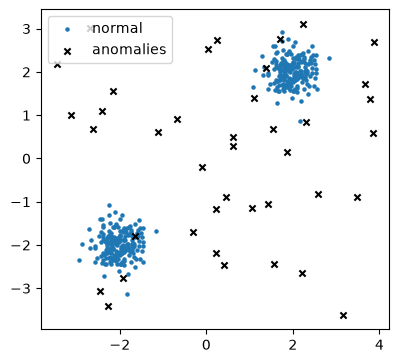

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score, precision_score, recall_score

# 400 normal points in two groups, 40 anomalies drawn in [-4, 4]²
rng = np.random.default_rng(0)
cluster = 0.3 * rng.standard_normal((200, 2))
X_normal = np.r_[cluster + 2, cluster - 2]
X_anomalies = rng.uniform(-4, 4, size=(40, 2))
X = np.r_[X_normal, X_anomalies]
is_anomaly = np.r_[np.zeros(len(X_normal), bool), np.ones(len(X_anomalies), bool)]


def report(title, predicted, score):
  """Points declared anomalous, precision and recall on the anomaly class."""
  print(f"{title}: {predicted.sum()} points declared anomalous")
  print(f"  precision {precision_score(is_anomaly, predicted):.2f}", end="")
  print(f", recall {recall_score(is_anomaly, predicted):.2f}", end="")
  print(
    f", area under the precision-recall curve {average_precision_score(is_anomaly, score):.2f}"
  )


def show_errors(ax, predicted):
  """The points, with the detection errors circled."""
  false_pos = predicted & ~is_anomaly
  false_neg = ~predicted & is_anomaly
  ax.scatter(*X_normal.T, s=5, color="C0", label="normal")
  ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
  ax.scatter(
    *X[false_pos].T,
    s=80,
    facecolors="none",
    edgecolors="C1",
    lw=1.5,
    label=f"false positives ({false_pos.sum()})",
  )
  ax.scatter(
    *X[false_neg].T,
    s=80,
    marker="s",
    facecolors="none",
    edgecolors="C3",
    lw=1.5,
    label=f"false negatives ({false_neg.sum()})",
  )
  ax.set_xlim(-5, 5)
  ax.set_ylim(-5, 5)
  ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(*X_normal.T, s=5, color="C0", label="normal")
ax.scatter(*X_anomalies.T, s=20, marker="x", color="k", label="anomalies")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## Score and Threshold

The detector gives an anomaly score per point (here `-score_samples`: the higher, the more anomalous the point); a threshold turns it into a decision (`predict`: −1 for an anomaly). This threshold is set by `contamination`, the expected share of anomalies. By default, `contamination="auto"` takes the original paper's threshold, 0.5:

In [3]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(random_state=0).fit(X)  # contamination="auto"
# anomaly score: the higher, the more anomalous the point
score = -model.score_samples(X)
report('contamination="auto"', model.predict(X) == -1, score)

contamination="auto": 62 points declared anomalous
  precision 0.61, recall 0.95, area under the precision-recall curve 0.94


The default threshold declares 62 points anomalous for 40 anomalies: it finds almost every anomaly (recall 0.95), but with 24 normal points (precision 0.61). It isn't the score that is wrong, it's the threshold. When the expected share of anomalies is known, give it to `contamination`: the threshold is then placed to declare that share of the points.

In [4]:
contamination = len(X_anomalies) / len(X)  # 40 / 440
model_real = IsolationForest(contamination=contamination, random_state=0).fit(X)
predicted = model_real.predict(X) == -1
report(f"contamination = {contamination:.3f}", predicted, score)

contamination = 0.091: 40 points declared anomalous
  precision 0.90, recall 0.90, area under the precision-recall curve 0.94


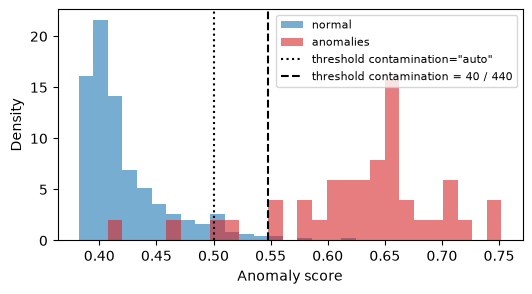

In [5]:
# The scores of the same model: only the threshold changes
bins = np.linspace(score.min(), score.max(), 30)
plt.figure(figsize=(6, 3))
plt.hist(score[~is_anomaly], bins=bins, density=True, alpha=0.6, label="normal")
plt.hist(
  score[is_anomaly], bins=bins, density=True, alpha=0.6, color="C3", label="anomalies"
)
plt.axvline(-model.offset_, color="k", ls=":", label='threshold contamination="auto"')
plt.axvline(
  -model_real.offset_, color="k", ls="--", label="threshold contamination = 40 / 440"
)
plt.xlabel("Anomaly score")
plt.ylabel("Density")
plt.legend(fontsize=8)
plt.show()

40 points declared for 40 anomalies: 36 anomalies found, 4 missed and 4 normal points wrongly declared, hence equal precision and recall (0.90). The area under the precision-recall curve doesn't change (0.94): it's the same score, only the threshold moved.

## The Score over the Plane

The anomaly score over the whole plane (darker: more anomalous), the threshold dashed, and the errors circled:

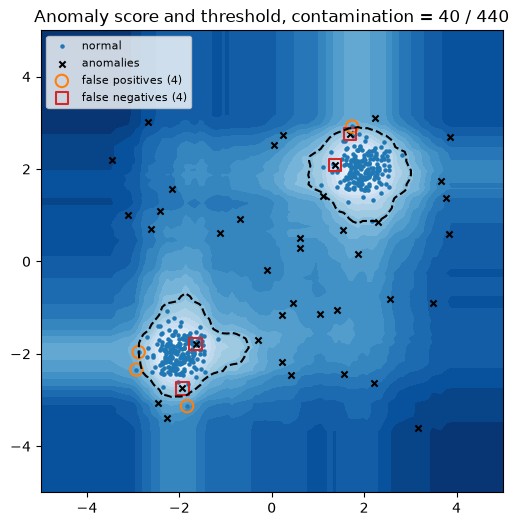

In [6]:
xx, yy = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
grid_score = -model_real.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(xx, yy, grid_score, levels=20, cmap="Blues")
ax.contour(
  xx, yy, grid_score, levels=[-model_real.offset_], colors="k", linestyles="--"
)
show_errors(ax, predicted)
ax.set_title("Anomaly score and threshold, contamination = 40 / 440")
ax.legend(loc="upper left", fontsize=8)
plt.show()

The normal points wrongly declared lie at the edge of the groups; the missed anomalies fell close to a group, where nothing sets them apart from the normal points: no detector would find them. Once trained, the forest also scores new points (`score_samples`, `predict`).